<a href="https://colab.research.google.com/github/AyushiChouhan25/naca63412-cfd-study/blob/main/final_project_1_code_for_plots_and_comparison_of_airfoils.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter number of airfoils to compare: 3
Enter air density [kg/m³] (default 1.225): 1.225
Enter freestream velocity [m/s] (default 15): 15
Enter airfoil chord [mm]: 200
Enter airfoil span/extrusion depth [mm]: 1200
Enter number of steady-state points (default 200): 200

          AIRFOIL 1
Enter name of Airfoil 1: NACA 66209

Upload CSV file for NACA 66209


Saving airfoil 1 force.csv to airfoil 1 force.csv
File uploaded: airfoil 1 force.csv
NACA 66209 analyzed successfully!

          AIRFOIL 2
Enter name of Airfoil 2: S6063

Upload CSV file for S6063


Saving airfoil 2 force.csv to airfoil 2 force.csv
File uploaded: airfoil 2 force.csv
S6063 analyzed successfully!

          AIRFOIL 3
Enter name of Airfoil 3: NACA 63412

Upload CSV file for NACA 63412


Saving airfoil 3 force.csv to airfoil 3 force.csv
File uploaded: airfoil 3 force.csv
NACA 63412 analyzed successfully!


       AIRFOIL CFD COMPARISON RESULTS

NACA 66209
--------------------------------
Lift             : 3.4400 N
Drag             : 0.7640 N
C_L              : 0.10401
C_D              : 0.02310
Pressure C_D     : 0.00989
Viscous C_D      : 0.01321
L/D              : 4.5026

S6063
--------------------------------
Lift             : 3.6256 N
Drag             : 0.7065 N
C_L              : 0.10962
C_D              : 0.02136
Pressure C_D     : 0.00880
Viscous C_D      : 0.01256
L/D              : 5.1320

NACA 63412
--------------------------------
Lift             : 7.7643 N
Drag             : 0.9383 N
C_L              : 0.23475
C_D              : 0.02837
Pressure C_D     : 0.01504
Viscous C_D      : 0.01333
L/D              : 8.2744


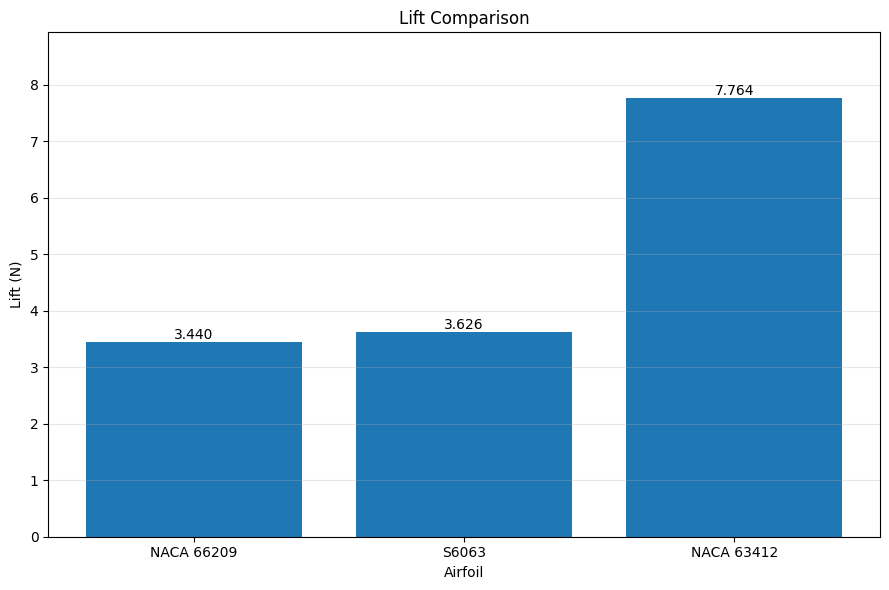

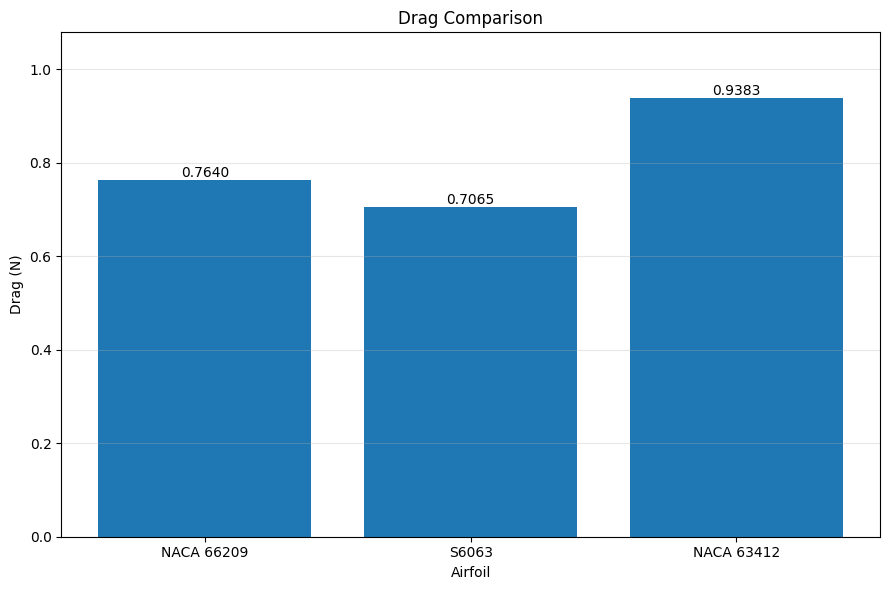

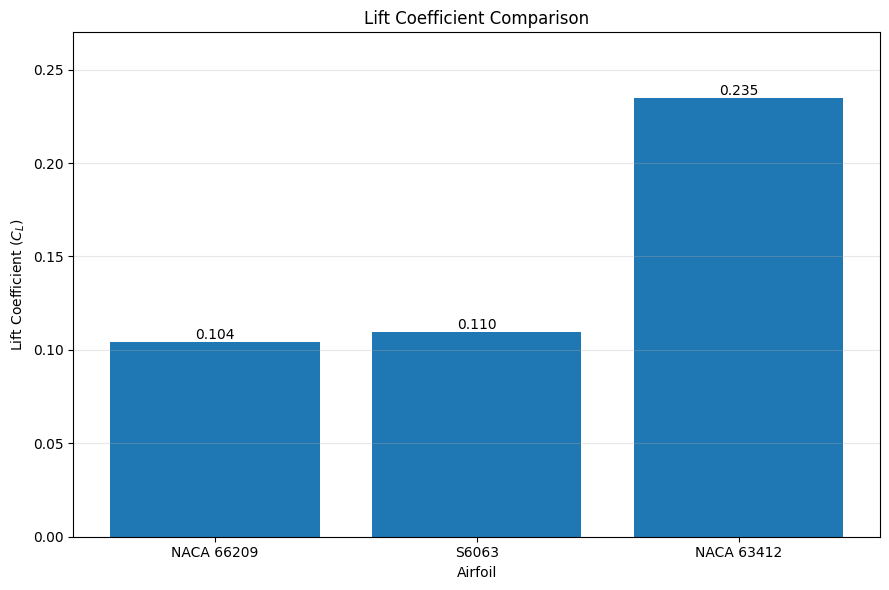

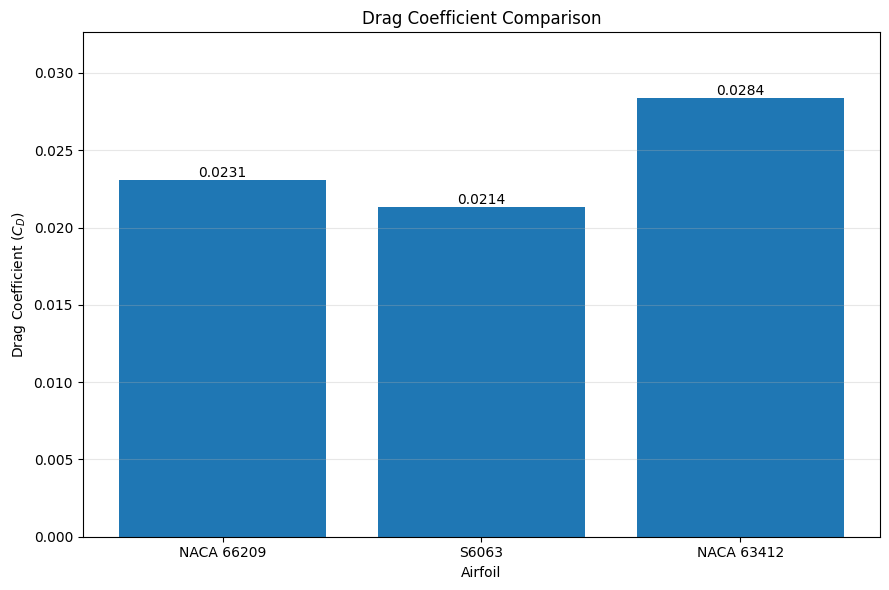

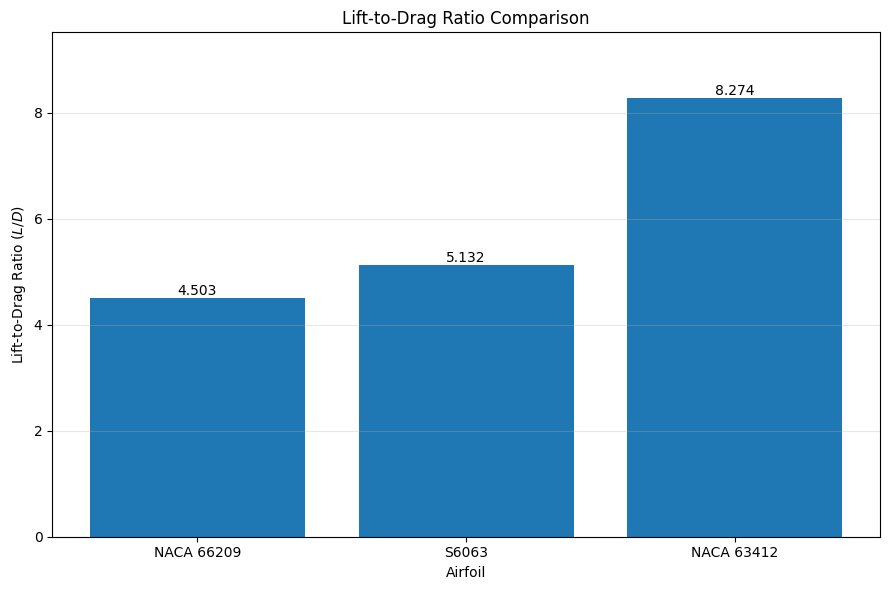


       ANALYSIS COMPLETE

Generated graphs:
1. Lift_Comparison.png
2. Drag_Comparison.png
3. CL_Comparison.png
4. CD_Comparison.png
5. LD_Comparison.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files



def analyze_airfoil(csv_filename, rho, velocity, chord_mm, span_mm, steady_steps=200):

    df = pd.read_csv(csv_filename)

    steady_df = df.tail(steady_steps)

    lift = steady_df['TOTAL_FORCE_Y'].mean()
    drag_total = steady_df['TOTAL_FORCE_X'].mean()

    drag_pressure = steady_df['PRESSURE_FORCE_X'].mean()
    drag_viscous = steady_df['VISCOUS_FORCE_X'].mean()

    # Convert mm → m
    chord = chord_mm / 1000
    span = span_mm / 1000

    # Reference area
    S = chord * span

    # Dynamic pressure
    q = 0.5 * rho * velocity**2

    # Aerodynamic coefficients
    c_l = lift / (q * S)
    c_d = drag_total / (q * S)

    c_dp = drag_pressure / (q * S)
    c_dv = drag_viscous / (q * S)

    # Lift-to-drag ratio
    ld_ratio = lift / drag_total

    # Return results
    return {
        "Lift": lift,
        "Drag": drag_total,
        "CL": c_l,
        "CD": c_d,
        "CD_pressure": c_dp,
        "CD_viscous": c_dv,
        "L/D": ld_ratio
    }


num_airfoils = int(input("Enter number of airfoils to compare: "))


# SIMULATION PARAMETERS
#

rho_input = input("Enter air density [kg/m³] (default 1.225): ")
rho = float(rho_input) if rho_input else 1.225

velocity_input = input("Enter freestream velocity [m/s] (default 15): ")
velocity = float(velocity_input) if velocity_input else 15.0

chord_mm = float(input("Enter airfoil chord [mm]: "))

span_mm = float(input("Enter airfoil span/extrusion depth [mm]: "))

steady_input = input("Enter number of steady-state points (default 200): ")
steady_steps = int(steady_input) if steady_input else 200


# ANALYZE AIRFOILS ONE BY ONE
#

results = {}

for i in range(num_airfoils):

    print("\n========================================")
    print(f"          AIRFOIL {i + 1}")
    print("========================================")

    airfoil_name = input(
        f"Enter name of Airfoil {i + 1}: "
    )

    print(f"\nUpload CSV file for {airfoil_name}")

    uploaded = files.upload()

    csv_filename = next(iter(uploaded))

    print(f"File uploaded: {csv_filename}")

    # Analyze
    results[airfoil_name] = analyze_airfoil(
        csv_filename,
        rho=rho,
        velocity=velocity,
        chord_mm=chord_mm,
        span_mm=span_mm,
        steady_steps=steady_steps
    )

    print(f"{airfoil_name} analyzed successfully!")


# DISPLAY RESULTS


print("\n")
print("================================================")
print("       AIRFOIL CFD COMPARISON RESULTS")
print("================================================")

for airfoil, data in results.items():

    print(f"\n{airfoil}")
    print("--------------------------------")

    print(f"Lift             : {data['Lift']:.4f} N")
    print(f"Drag             : {data['Drag']:.4f} N")

    print(f"C_L              : {data['CL']:.5f}")
    print(f"C_D              : {data['CD']:.5f}")

    print(f"Pressure C_D     : {data['CD_pressure']:.5f}")
    print(f"Viscous C_D      : {data['CD_viscous']:.5f}")

    print(f"L/D              : {data['L/D']:.4f}")


# PREPARE GRAPH DATA

airfoils = list(results.keys())

lift = [results[a]["Lift"] for a in airfoils]
drag = [results[a]["Drag"] for a in airfoils]

CL = [results[a]["CL"] for a in airfoils]
CD = [results[a]["CD"] for a in airfoils]

LD = [results[a]["L/D"] for a in airfoils]


# GRAPH 1 — LIFT
#

plt.figure(figsize=(9, 6))

plt.bar(airfoils, lift)

plt.xlabel("Airfoil")
plt.ylabel("Lift (N)")
plt.title("Lift Comparison")

for i, value in enumerate(lift):
    plt.text(
        i,
        value,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.ylim(0, max(lift) * 1.15)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("Lift_Comparison.png", dpi=300, bbox_inches="tight")

plt.show()


# GRAPH 2 — DRAG

plt.figure(figsize=(9, 6))

plt.bar(airfoils, drag)

plt.xlabel("Airfoil")
plt.ylabel("Drag (N)")
plt.title("Drag Comparison")

for i, value in enumerate(drag):
    plt.text(
        i,
        value,
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

plt.ylim(0, max(drag) * 1.15)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("Drag_Comparison.png", dpi=300, bbox_inches="tight")

plt.show()


# GRAPH 3 — CL

plt.figure(figsize=(9, 6))

plt.bar(airfoils, CL)

plt.xlabel("Airfoil")
plt.ylabel("Lift Coefficient ($C_L$)")
plt.title("Lift Coefficient Comparison")

for i, value in enumerate(CL):
    plt.text(
        i,
        value,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.ylim(0, max(CL) * 1.15)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("CL_Comparison.png", dpi=300, bbox_inches="tight")

plt.show()


# GRAPH 4 — CD

plt.figure(figsize=(9, 6))

plt.bar(airfoils, CD)

plt.xlabel("Airfoil")
plt.ylabel("Drag Coefficient ($C_D$)")
plt.title("Drag Coefficient Comparison")

for i, value in enumerate(CD):
    plt.text(
        i,
        value,
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

plt.ylim(0, max(CD) * 1.15)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("CD_Comparison.png", dpi=300, bbox_inches="tight")

plt.show()


# GRAPH 5 — L/D

plt.figure(figsize=(9, 6))

plt.bar(airfoils, LD)

plt.xlabel("Airfoil")
plt.ylabel("Lift-to-Drag Ratio ($L/D$)")
plt.title("Lift-to-Drag Ratio Comparison")

for i, value in enumerate(LD):
    plt.text(
        i,
        value,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.ylim(0, max(LD) * 1.15)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("LD_Comparison.png", dpi=300, bbox_inches="tight")

plt.show()


print("\n================================================")
print("       ANALYSIS COMPLETE")
print("================================================")

print("\nGenerated graphs:")
print("1. Lift_Comparison.png")
print("2. Drag_Comparison.png")
print("3. CL_Comparison.png")
print("4. CD_Comparison.png")
print("5. LD_Comparison.png")

1 = Mesh independence study (fixed angle, several meshes)
2 = Angle-of-attack sweep (fixed mesh, several angles)
Choose study: 2
Air density [kg/m3] (default 1.225): 1.225
Freestream velocity [m/s] (default 15): 15
Chord [mm]: 200
Span / extrusion depth [mm]: 1200
Steady-state points to average (default 100): 200
Number of angles of attack (e.g. 5): 1

Angle of attack of run 1 [deg]: 16

Upload CSV file for alpha = 16 deg


Saving AoA_12 degree.csv to AoA_12 degree (1).csv

   ANGLE-OF-ATTACK SWEEP RESULTS
 Alpha    Lift   Drag     CL     CD  CD_pressure  CD_viscous    L/D  Spread_%
  16.0 12.4501 4.2604 0.3764 0.1288       0.1163      0.0126 2.9223    0.0477

Max L/D = 2.92 at alpha = 16 deg
Max CL  = 0.376 at alpha = 16 deg


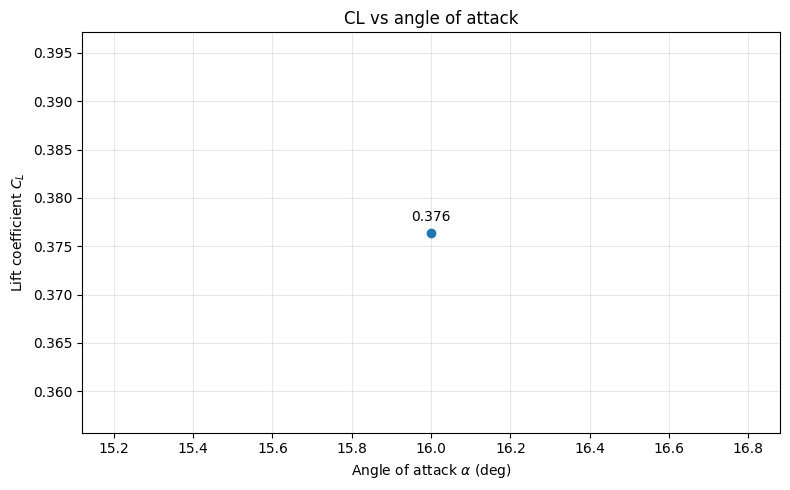

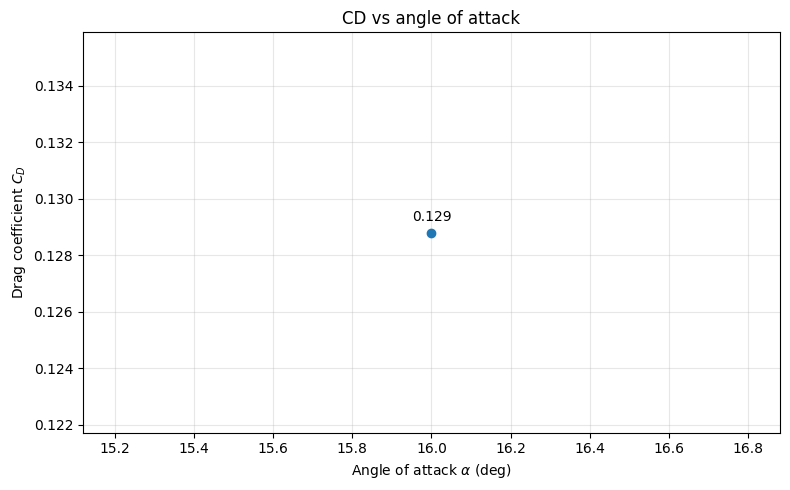

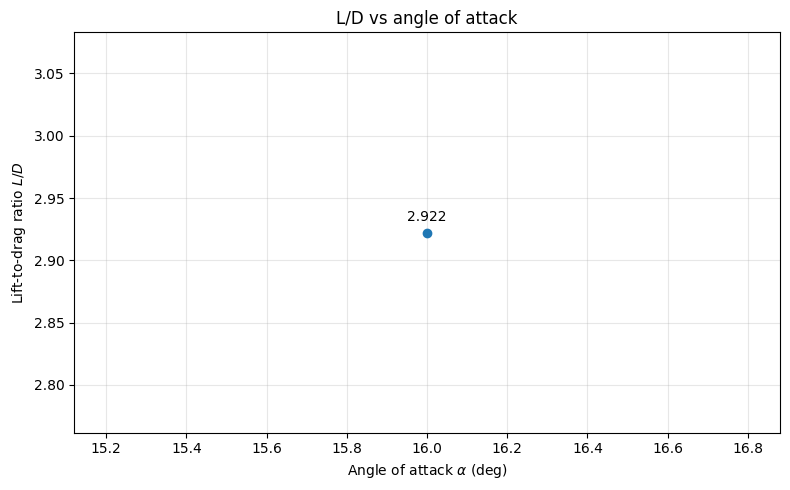

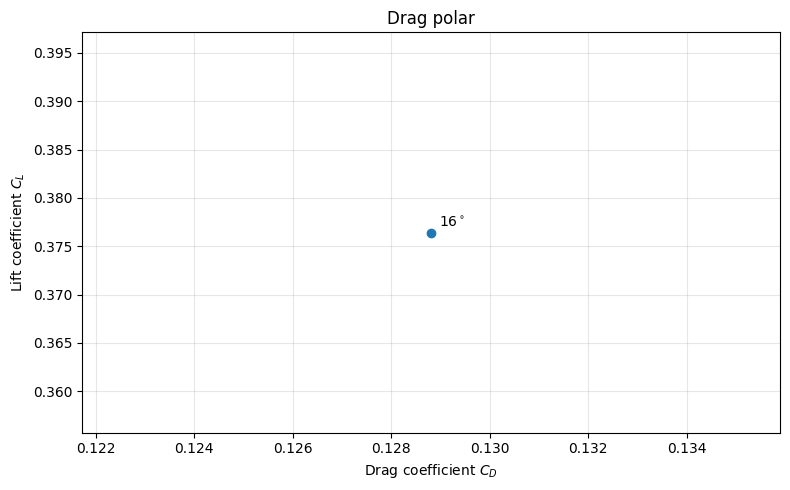


       ANALYSIS COMPLETE


In [ ]:
# PROJECT 2 - MESH INDEPENDENCE + ANGLE-OF-ATTACK ANALYSIS


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False



def get_csv(label):
    if IN_COLAB:
        print(f"\nUpload CSV file for {label}")
        uploaded = files.upload()
        return next(iter(uploaded))
    return input(f"Path to CSV for {label}: ").strip()


# FUNCTION: ANALYZE ONE RUN

def analyze_run(csv_filename, alpha_deg, rho, velocity, chord_mm, span_mm, steady_steps=200):

    df = pd.read_csv(csv_filename)
    df.columns = [c.strip() for c in df.columns]
    steady_df = df.tail(steady_steps)

    Fx = steady_df['TOTAL_FORCE_X'].mean()
    Fy = steady_df['TOTAL_FORCE_Y'].mean()
    Fx_p = steady_df['PRESSURE_FORCE_X'].mean()
    Fy_p = steady_df['PRESSURE_FORCE_Y'].mean()
    Fx_v = steady_df['VISCOUS_FORCE_X'].mean()
    Fy_v = steady_df['VISCOUS_FORCE_Y'].mean()

    # Rotate into WIND axes
    a = np.radians(alpha_deg)
    drag = Fx * np.cos(a) + Fy * np.sin(a)
    lift = -Fx * np.sin(a) + Fy * np.cos(a)
    drag_p = Fx_p * np.cos(a) + Fy_p * np.sin(a)
    drag_v = Fx_v * np.cos(a) + Fy_v * np.sin(a)

    S = (chord_mm / 1000) * (span_mm / 1000)
    q = 0.5 * rho * velocity**2

    # Convergence check: spread of Fy over the averaging window (% of mean)
    spread = (steady_df['TOTAL_FORCE_Y'].max() - steady_df['TOTAL_FORCE_Y'].min()) / abs(Fy) * 100

    return {
        "Alpha": alpha_deg,
        "Lift": lift,
        "Drag": drag,
        "CL": lift / (q * S),
        "CD": drag / (q * S),
        "CD_pressure": drag_p / (q * S),
        "CD_viscous": drag_v / (q * S),
        "L/D": lift / drag,
        "Spread_%": spread,
    }


# SIMULATION PARAMETERS

print("1 = Mesh independence study (fixed angle, several meshes)")
print("2 = Angle-of-attack sweep (fixed mesh, several angles)")
mode = int(input("Choose study: "))

rho_input = input("Air density [kg/m3] (default 1.225): ")
rho = float(rho_input) if rho_input else 1.225

velocity_input = input("Freestream velocity [m/s] (default 15): ")
velocity = float(velocity_input) if velocity_input else 15.0

chord_mm = float(input("Chord [mm]: "))
span_mm = float(input("Span / extrusion depth [mm]: "))

steady_input = input("Steady-state points to average (default 100): ")
steady_steps = int(steady_input) if steady_input else 100



# STUDY 1 - MESH INDEPENDENCE

if mode == 1:

    alpha = float(input("Angle of attack used for ALL meshes [deg] (e.g. 4): "))
    n = int(input("Number of meshes (e.g. 3): "))

    rows = []
    for i in range(n):
        name = input(f"\nName of mesh {i + 1} (e.g. Coarse): ")
        cells = float(input(f"Cell count of {name} (e.g. 520000): "))
        csv = get_csv(name)
        r = analyze_run(csv, alpha, rho, velocity, chord_mm, span_mm, steady_steps)
        r["Mesh"] = name
        r["Cells"] = cells
        rows.append(r)

    res = pd.DataFrame(rows).sort_values("Cells").reset_index(drop=True)

    # Percentage change between consecutive meshes: |X2 - X1| / X1 * 100
    res["dCL_%"] = res["CL"].pct_change().abs() * 100
    res["dCD_%"] = res["CD"].pct_change().abs() * 100
    res["dLD_%"] = res["L/D"].pct_change().abs() * 100

    print("\n================================================")
    print(f"   MESH INDEPENDENCE RESULTS  (alpha = {alpha:.1f} deg)")
    print("================================================")
    print(res[["Mesh", "Cells", "Lift", "Drag", "CL", "CD", "L/D",
               "dCL_%", "dCD_%", "Spread_%"]].round(4).to_string(index=False))

    last = res.iloc[-1]
    print("\nLast refinement step:")
    print(f"  dCL = {last['dCL_%']:.2f} %   {'OK (<2%)' if last['dCL_%'] < 2 else 'NOT converged'}")
    print(f"  dCD = {last['dCD_%']:.2f} %   {'OK (<2%)' if last['dCD_%'] < 2 else 'NOT converged'}")

    res.to_csv("mesh_independence_results.csv", index=False)

    for col, ylabel, fname in [("CL", "Lift coefficient $C_L$", "Mesh_CL.png"),
                               ("CD", "Drag coefficient $C_D$", "Mesh_CD.png"),
                               ("Lift", "Lift (N)", "Mesh_Lift.png"),
                               ("Drag", "Drag (N)", "Mesh_Drag.png")]:
        plt.figure(figsize=(8, 5))
        plt.plot(res["Cells"], res[col], "o-", linewidth=2)
        for x, y in zip(res["Cells"], res[col]):
            plt.annotate(f"{y:.4f}", (x, y), textcoords="offset points",
                         xytext=(0, 8), ha="center")
        plt.xlabel("Number of mesh cells")
        plt.ylabel(ylabel)
        plt.title(f"Mesh independence: {col} ($\\alpha$ = {alpha:.0f}$^\\circ$)")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.savefig(fname, dpi=300, bbox_inches="tight")
        plt.show()


# STUDY 2 - ANGLE-OF-ATTACK SWEEP

elif mode == 2:

    n = int(input("Number of angles of attack (e.g. 5): "))

    rows = []
    for i in range(n):
        alpha = float(input(f"\nAngle of attack of run {i + 1} [deg]: "))
        csv = get_csv(f"alpha = {alpha:.0f} deg")
        rows.append(analyze_run(csv, alpha, rho, velocity, chord_mm, span_mm, steady_steps))

    res = pd.DataFrame(rows).sort_values("Alpha").reset_index(drop=True)

    print("\n================================================")
    print("   ANGLE-OF-ATTACK SWEEP RESULTS")
    print("================================================")
    print(res.round(4).to_string(index=False))

    # Lift-curve slope over the linear region (alpha <= 8 deg)
    lin = res[res["Alpha"] <= 8]
    if len(lin) >= 2:
        slope, intercept = np.polyfit(lin["Alpha"], lin["CL"], 1)
        print(f"\nLift-curve slope (alpha <= 8 deg): {slope:.4f} per degree")
        print("  Reference: thin-airfoil 2D = 0.1097 /deg; finite wing (AR=6) about 0.08 /deg")
        if slope != 0:
            print(f"  Zero-lift angle from fit: {-intercept / slope:.2f} deg")

    best = res.loc[res["L/D"].idxmax()]
    print(f"\nMax L/D = {best['L/D']:.2f} at alpha = {best['Alpha']:.0f} deg")
    print(f"Max CL  = {res['CL'].max():.3f} at alpha = {res.loc[res['CL'].idxmax(), 'Alpha']:.0f} deg")

    res.to_csv("aoa_sweep_results.csv", index=False)

    plots = [("CL", "Lift coefficient $C_L$", "AoA_CL.png"),
             ("CD", "Drag coefficient $C_D$", "AoA_CD.png"),
             ("L/D", "Lift-to-drag ratio $L/D$", "AoA_LD.png")]

    for col, ylabel, fname in plots:
        plt.figure(figsize=(8, 5))
        plt.plot(res["Alpha"], res[col], "o-", linewidth=2)
        for x, y in zip(res["Alpha"], res[col]):
            plt.annotate(f"{y:.3f}", (x, y), textcoords="offset points",
                         xytext=(0, 8), ha="center")
        plt.xlabel("Angle of attack $\\alpha$ (deg)")
        plt.ylabel(ylabel)
        plt.title(f"{col} vs angle of attack")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.savefig(fname, dpi=300, bbox_inches="tight")
        plt.show()

    # Drag polar
    plt.figure(figsize=(8, 5))
    plt.plot(res["CD"], res["CL"], "o-", linewidth=2)
    for x, y, a in zip(res["CD"], res["CL"], res["Alpha"]):
        plt.annotate(f"{a:.0f}$^\\circ$", (x, y), textcoords="offset points",
                     xytext=(6, 4))
    plt.xlabel("Drag coefficient $C_D$")
    plt.ylabel("Lift coefficient $C_L$")
    plt.title("Drag polar")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("AoA_Polar.png", dpi=300, bbox_inches="tight")
    plt.show()

else:
    print("Invalid choice. Enter 1 or 2.")

print("\n================================================")
print("       ANALYSIS COMPLETE")
print("================================================")